# Giá trị thiếu trên mọi đặc trưng (dữ liệu thô)

Notebook vẽ toàn bộ giá trị thiếu của `raw_data_oto.csv` **trước mọi bước làm sạch** (chưa xóa trùng, chưa loại giá sai). Ảnh lưu ở `figures/` với tiền tố `v`.

**Thế nào là "thiếu" trong dữ liệu thô** (khớp với `preprocess_data.ipynb`):

| Ghi trong file | Nguồn gốc | Coi là |
|---|---|---|
| `N/A` | code crawl không tìm thấy thẻ trên trang (người bán bỏ trống, hoặc trang không có ô đó) | thiếu |
| `Đang cập nhật` | trang tự hiện khi người bán không chọn xuất xứ | thiếu |
| `Khác` ở `carseats` | số chỗ không xác định, không đổi ra số được | thiếu |
| `Khác` / `Dòng khác` ở cột khác | người bán chủ động chọn trong danh sách | **không** thiếu (nhãn thật) |

Cột `no` (số thứ tự) không phải đặc trưng nên không vẽ.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"
INK, INK2, GRID, PALE = "#0b0b0b", "#52514e", "#e6e5e1", "#f1f0ec"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

def vn(x, d=0):
    """Định dạng số kiểu Việt Nam: 1.234,5"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "_").replace(".", ",").replace("_", ".")

## 1. Đọc dữ liệu thô và đánh dấu ô thiếu
Đọc mọi cột dạng chuỗi với `keep_default_na=False` để thấy đúng chữ ghi trong file, rồi đánh dấu thiếu theo bảng ở trên.

In [2]:
raw = pd.read_csv("raw_data_oto.csv", dtype=str, keep_default_na=False)
FEATS = [c for c in raw.columns if c != "no"]

VI = {"url": "Đường dẫn (url)", "mileage_v2": "Số km (mileage_v2)", "carorigin": "Xuất xứ (carorigin)",
      "condition_ad": "Tình trạng (condition_ad)", "veh_warranty_policy": "Bảo hành (veh_warranty_policy)",
      "carbrand": "Hãng (carbrand)", "carmodel": "Dòng xe (carmodel)", "mfdate": "Năm SX (mfdate)",
      "gearbox": "Hộp số (gearbox)", "fuel": "Nhiên liệu (fuel)", "cartype": "Kiểu dáng (cartype)",
      "carseats": "Số chỗ (carseats)", "price": "Giá (price)"}
SHORT = {c: v.split(" (")[0] for c, v in VI.items()}

# Ba nguồn thiếu, tách riêng để vẽ
na_tag   = raw[FEATS].isin(["N/A", ""])
updating = raw[FEATS] == "Đang cập nhật"
seat_oth = pd.DataFrame(False, index=raw.index, columns=FEATS)
seat_oth["carseats"] = raw["carseats"] == "Khác"
miss = na_tag | updating | seat_oth

summary = pd.DataFrame({
    "N/A (không có thẻ)": na_tag.sum(),
    "Đang cập nhật": updating.sum(),
    "Khác (số chỗ)": seat_oth.sum(),
    "tổng thiếu": miss.sum(),
})
summary["% thiếu"] = (summary["tổng thiếu"] / len(raw) * 100).round(2)
print(f"{len(raw):,} tin, {len(FEATS)} đặc trưng; {miss.any(axis=1).sum():,} tin thiếu ít nhất một ô "
      f"({miss.any(axis=1).mean():.1%}); tổng {miss.values.sum():,} ô thiếu")
summary.sort_values("tổng thiếu", ascending=False)

14,835 tin, 13 đặc trưng; 9,370 tin thiếu ít nhất một ô (63.2%); tổng 16,394 ô thiếu


,N/A (không có thẻ),Đang cập nhật,Khác (số chỗ),tổng thiếu,% thiếu
carorigin,0,6012,0,6012,40.53
cartype,4883,0,0,4883,32.92
carseats,3028,0,659,3687,24.85
mileage_v2,1811,0,0,1811,12.21
price,1,0,0,1,0.01
veh_warranty_policy,0,0,0,0,0.00
condition_ad,0,0,0,0,0.00
url,0,0,0,0,0.00
carbrand,0,0,0,0,0.00
gearbox,0,0,0,0,0.00


## 2. Tỉ lệ thiếu trên toàn bộ đặc trưng
Vẽ cả các cột **không thiếu** (0%) để thấy bức tranh đầy đủ. Mỗi thanh chia theo nguồn thiếu.

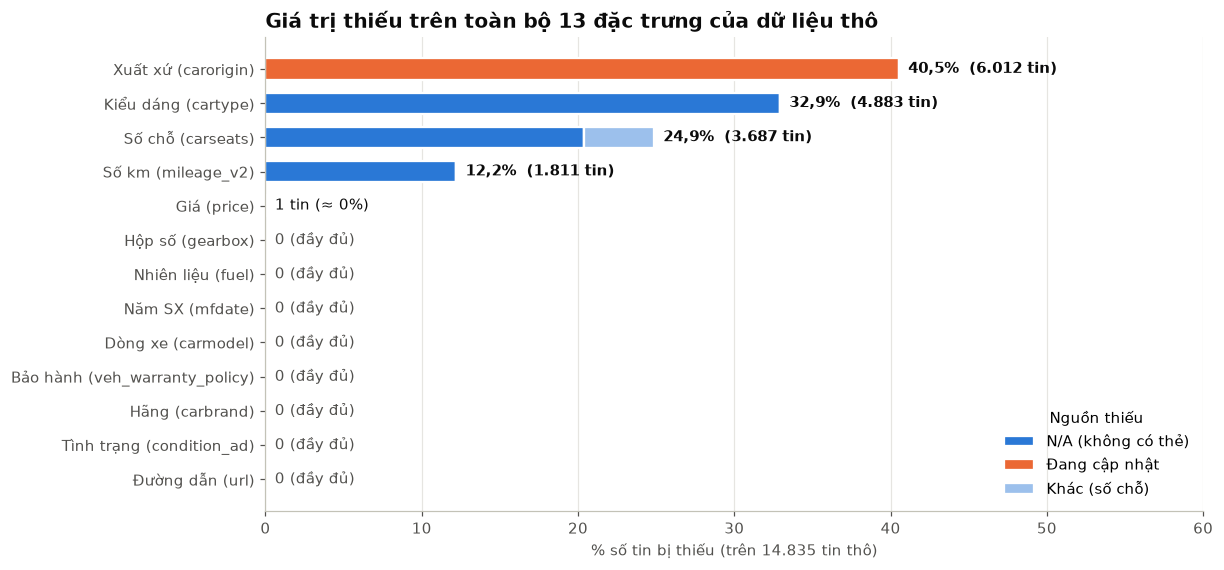

In [3]:
order = summary.sort_values("tổng thiếu").index        # ít thiếu ở dưới, nhiều ở trên
parts = [("N/A (không có thẻ)", BLUE), ("Đang cập nhật", ORANGE), ("Khác (số chỗ)", "#9cc0ec")]
n = len(raw)

fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(order))
left = np.zeros(len(order))
for col, color in parts:
    w = summary.loc[order, col].values / n * 100
    ax.barh(y, w, left=left, color=color, height=0.62, label=col, edgecolor="white", linewidth=1.5)
    left += w
for i, c in enumerate(order):
    t, p = summary.loc[c, "tổng thiếu"], summary.loc[c, "% thiếu"]
    if t == 0:
        lab = "0 (đầy đủ)"
    elif p < 0.1:
        lab = f"{vn(t)} tin (≈ 0%)"
    else:
        lab = f"{vn(p, 1)}%  ({vn(t)} tin)"
    ax.text(left[i] + 0.6, i, lab, va="center", color=INK if t else INK2, fontsize=9.5,
            fontweight="bold" if p >= 5 else "normal")
ax.set_yticks(y); ax.set_yticklabels([VI[c] for c in order])
ax.set_xlim(0, 60); ax.set_xlabel(f"% số tin bị thiếu (trên {vn(n)} tin thô)")
ax.set_title("Giá trị thiếu trên toàn bộ 13 đặc trưng của dữ liệu thô")
ax.grid(axis="y", visible=False)
ax.legend(title="Nguồn thiếu", loc="lower right", frameon=False)
save(fig, "v01_thieu_moi_dac_trung")

**Đọc biểu đồ:**
- Chỉ **5/13** cột có thiếu. 8 cột còn lại (hãng, dòng, năm, hộp số, nhiên liệu, tình trạng, bảo hành, url) đầy đủ 100% vì là ô bắt buộc hoặc do trang tự sinh.
- **Xuất xứ** thiếu nhiều nhất, toàn bộ ở dạng `Đang cập nhật`. **Kiểu dáng** và **số chỗ** thiếu vì là ô không bắt buộc; số chỗ có thêm phần `Khác`.
- **Số km** thiếu chủ yếu ở xe mới (xem mục 4).
- **Giá** chỉ thiếu 1 tin → xóa ở bước tiền xử lý (không điền biến mục tiêu).

## 3. Ma trận thiếu: ô thiếu nằm ở đâu, có đi cùng nhau không
Mỗi dòng ngang là một tin, mỗi cột là một đặc trưng; ô xanh là thiếu. Các tin được xếp theo tình trạng xe (xe mới ở trên) rồi theo kiểu thiếu, để thấy các mẫu thiếu lặp lại.

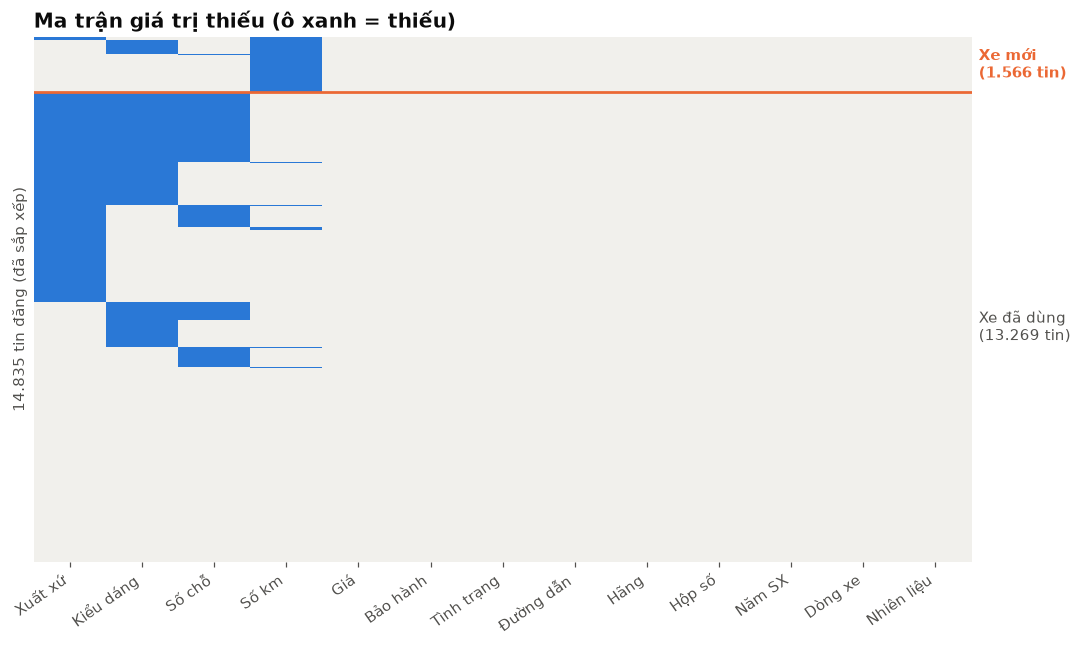

,số tin,%
(không thiếu ô nào),5465,36.8
Xuất xứ,2026,13.7
Xuất xứ + Kiểu dáng + Số chỗ,1933,13.0
Xuất xứ + Kiểu dáng,1201,8.1
Số km,1101,7.4
Kiểu dáng,762,5.1
Xuất xứ + Số chỗ,582,3.9
Số chỗ,534,3.6


In [4]:
cols = summary.sort_values("tổng thiếu", ascending=False).index.tolist()
is_new = (raw["condition_ad"] == "Mới").astype(int)
sort_key = pd.concat([is_new.rename("_new"), miss[cols].astype(int)], axis=1)
idx = sort_key.sort_values(["_new"] + cols, ascending=False).index
mat = miss.loc[idx, cols].values.astype(float)

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.imshow(mat, aspect="auto", cmap=ListedColormap([PALE, BLUE]), interpolation="nearest")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([SHORT[c] for c in cols], rotation=35, ha="right")
n_new = int(is_new.sum())
ax.axhline(n_new - 0.5, color=ORANGE, lw=1.8)
ax.text(len(cols) - 0.4, n_new / 2, f"Xe mới\n({vn(n_new)} tin)", color=ORANGE,
        va="center", ha="left", fontsize=9.5, fontweight="bold")
ax.text(len(cols) - 0.4, n_new + (len(raw) - n_new) / 2, f"Xe đã dùng\n({vn(len(raw) - n_new)} tin)",
        color=INK2, va="center", ha="left", fontsize=9.5)
ax.set_ylabel(f"{vn(len(raw))} tin đăng (đã sắp xếp)"); ax.set_yticks([])
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Ma trận giá trị thiếu (ô xanh = thiếu)")
save(fig, "v02_ma_tran_thieu")

# Các tổ hợp thiếu hay gặp nhất
combo = miss[cols].apply(lambda r: " + ".join(SHORT[c] for c in cols if r[c]) or "(không thiếu ô nào)", axis=1)
top = combo.value_counts().head(8).rename("số tin").to_frame()
top["%"] = (top["số tin"] / len(raw) * 100).round(1)
top

**Đọc ma trận:**
- **Số km:** cột số km gần như xanh kín ở vùng xe mới → thiếu **có cấu trúc** (trang xe mới không có ô km), không phải ngẫu nhiên. Vì vậy tiền xử lý điền **0 km** cho xe mới thay vì trung vị.
- **Kiểu dáng và số chỗ** hay thiếu **cùng lúc**: người bán bỏ qua cả nhóm ô không bắt buộc. Cả hai đều suy được từ dòng xe nên được điền theo dòng xe.
- **Xuất xứ** thiếu thành một khối lớn ở xe đã dùng, thường đi cùng kiểu dáng và số chỗ (tổ hợp "Xuất xứ + Kiểu dáng + Số chỗ" chiếm 13% số tin). Xuất xứ không suy được từ dòng xe (cùng dòng có thể nhập khẩu hoặc lắp ráp) → giữ nhãn "Không rõ".
- Khoảng **37%** số tin đầy đủ mọi ô; nếu xóa mọi dòng có thiếu sẽ mất gần 2/3 dữ liệu, nên phải điền chứ không xóa.

## 4. Tỉ lệ thiếu theo tình trạng xe
Kiểm tra bằng số: thiếu ở mỗi cột có phụ thuộc vào việc xe mới hay đã dùng không. Nếu tỉ lệ khác hẳn nhau giữa hai nhóm thì thiếu **không ngẫu nhiên** và cách điền phải tính đến điều đó.

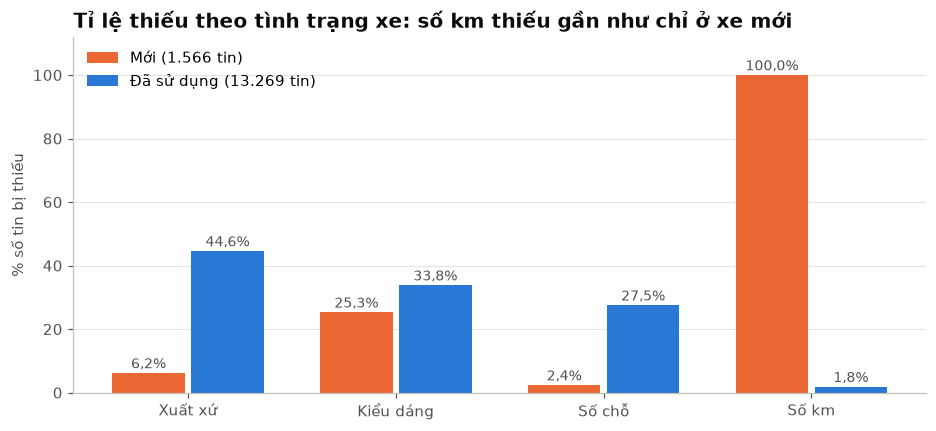

condition_ad,Mới,Đã sử dụng
carorigin,6.2,44.6
cartype,25.3,33.8
carseats,2.4,27.5
mileage_v2,100.0,1.8


In [5]:
miss_cols = [c for c in cols if summary.loc[c, "tổng thiếu"] > 1]
by_cond = (miss[miss_cols].groupby(raw["condition_ad"]).mean().T * 100)[["Mới", "Đã sử dụng"]]

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(miss_cols)); w = 0.38
for k, (cond, color) in enumerate([("Mới", ORANGE), ("Đã sử dụng", BLUE)]):
    vals = by_cond[cond].values
    ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=color,
           label=f"{cond} ({vn((raw['condition_ad'] == cond).sum())} tin)")
    for xi, v in zip(x, vals):
        ax.text(xi + (k - 0.5) * w, v + 1.5, f"{vn(v, 1)}%", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([SHORT[c] for c in miss_cols])
ax.set_ylim(0, 112); ax.set_ylabel("% số tin bị thiếu")
ax.set_title("Tỉ lệ thiếu theo tình trạng xe: số km thiếu gần như chỉ ở xe mới")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper left")
save(fig, "v03_thieu_theo_tinh_trang")
by_cond.round(1)

**Đọc biểu đồ:**
- **Số km:** xe mới thiếu 100%, xe đã dùng chỉ 1,8% → thiếu có cấu trúc, xác nhận cách điền 0 km cho xe mới.
- **Xuất xứ, số chỗ** thiếu chủ yếu ở xe đã dùng (44,6% và 27,5%, so với 6,2% và 2,4% ở xe mới): tin xe mới thường do đại lý đăng, điền đầy đủ hơn người bán cá nhân.
- **Kiểu dáng** thiếu ở cả hai nhóm (25-34%).

**Kết luận cho tiền xử lý:**

| Cột | Kiểu thiếu | Cách xử lý (ở `preprocess_data.ipynb`) |
|---|---|---|
| Số km | có cấu trúc: xe mới không có ô km | xe mới = 0 km; xe cũ thiếu: trung vị theo đời xe + cột `mileage_missing` |
| Kiểu dáng | ô không bắt buộc, suy được từ dòng xe | mode theo dòng xe, còn lại "Không rõ" |
| Số chỗ | ô không bắt buộc (+ "Khác"), suy được từ dòng xe | mode theo dòng xe, rồi theo hãng |
| Xuất xứ | ô không bắt buộc, không suy được | nhãn "Không rõ" |
| Giá | 1 tin | xóa dòng (không điền biến mục tiêu) |
| 8 cột còn lại | không thiếu | không cần xử lý |

Lưu ý: số liệu ở đây là trên **dữ liệu thô** (14.835 tin, còn tin trùng). Hình `p02` trong `preprocess_data.ipynb` tính sau khi xóa trùng nên tỉ lệ hơi khác.

## 5. Cơ cấu kiểu dáng, số chỗ, xuất xứ (có tính phần thiếu)
Cùng kiểu với hình `02_co_cau`: mỗi thanh là % số tin của một giá trị. Khác ở chỗ phần **thiếu** được vẽ thành thanh xám riêng, vì ba cột này là ô không bắt buộc và thiếu nhiều (xem mục 2). Nếu bỏ phần thiếu đi rồi tính % thì sẽ không thấy được 1/3 đến 2/5 dữ liệu không có thông tin.

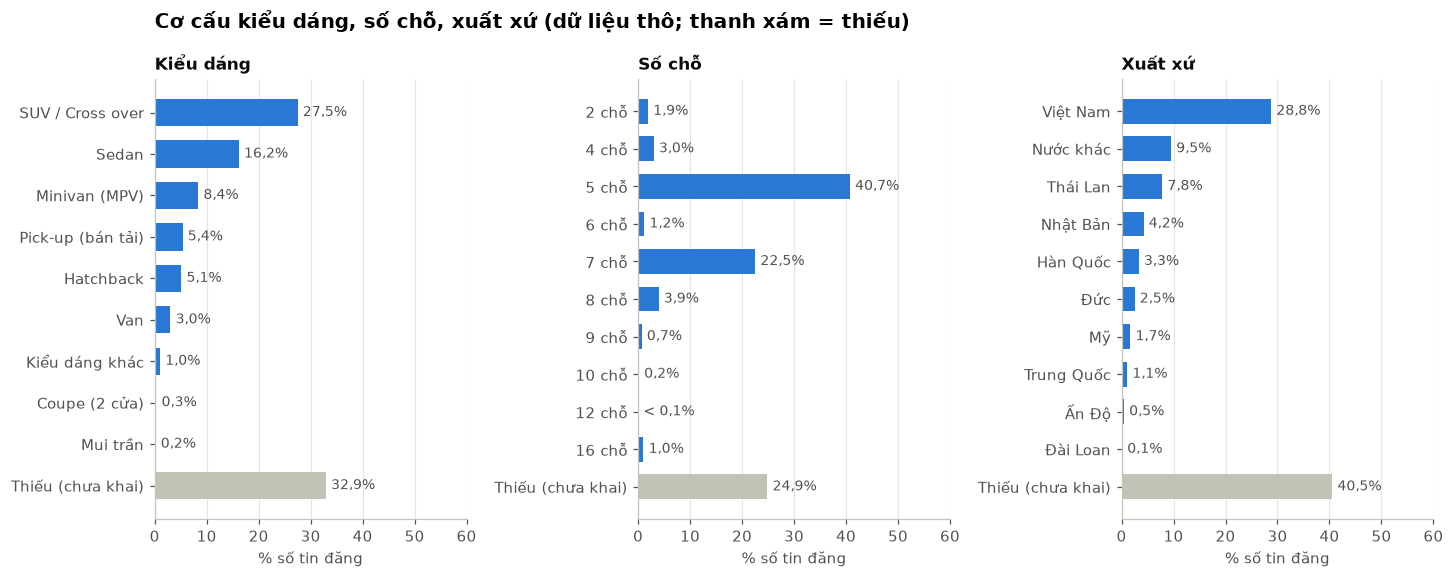

% số tin
Kiểu dáng SUV / Cross over       27.5
          Sedan                  16.2
          Minivan (MPV)           8.4
          Pick-up (bán tải)       5.4
          Hatchback               5.1
          Van                     3.0
          Kiểu dáng khác          1.0
          Coupe (2 cửa)           0.3
          Mui trần                0.2
          Thiếu (chưa khai)      32.9
Số chỗ    2 chỗ                   1.9
          4 chỗ                   3.0
          5 chỗ                  40.7
          6 chỗ                   1.2
          7 chỗ                  22.5
          8 chỗ                   3.9
          9 chỗ                   0.7
          10 chỗ                  0.2
          12 chỗ                  0.0
          16 chỗ                  1.0
          Thiếu (chưa khai)      24.9
Xuất xứ   Việt Nam               28.8
          Nước khác               9.5
          Thái Lan                7.8
          Nhật Bản                4.2
          Hàn Quốc                3.3
          Đức                     2.5
          Mỹ                      1.7
          Trung Quốc              1.1
          Ấn Độ                   0.5
          Đài Loan                0.1
          Thiếu (chưa khai)      40.5

In [6]:
MISS_LABEL = "Thiếu (chưa khai)"

def share_with_missing(ax, col, title, rename=None, order=None):
    s = raw[col].where(~miss[col], MISS_LABEL)
    if rename: s = s.map(lambda v: rename.get(v, v))
    pct = s.value_counts(normalize=True) * 100
    known = pct.drop(MISS_LABEL, errors="ignore")
    known = known.reindex(order) if order else known.sort_values(ascending=False)
    pct = pd.concat([known, pct[[MISS_LABEL]]]) if MISS_LABEL in pct else known
    y = np.arange(len(pct))[::-1]                     # giá trị lớn ở trên, thiếu ở dưới cùng
    colors = [GRAY if k == MISS_LABEL else BLUE for k in pct.index]
    ax.barh(y, pct.values, color=colors, height=0.66)
    for yi, v in zip(y, pct.values):
        ax.text(v + 1, yi, f"{vn(v, 1)}%" if v >= 0.05 else "< 0,1%", va="center", color=INK2, fontsize=9)
    ax.set_yticks(y); ax.set_yticklabels(pct.index)
    ax.set_xlim(0, 60); ax.set_xlabel("% số tin đăng")
    ax.set_title(title, fontsize=11); ax.grid(axis="y", visible=False)
    return pct

seat_order = [str(k) for k in sorted(int(v) for v in raw["carseats"][~miss["carseats"]].unique())]
seat_name = {k: f"{k} chỗ" for k in seat_order}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"wspace": 0.55})
p_type = share_with_missing(axes[0], "cartype", "Kiểu dáng")
p_seat = share_with_missing(axes[1], "carseats", "Số chỗ", rename=seat_name, order=[seat_name[k] for k in seat_order])
p_orig = share_with_missing(axes[2], "carorigin", "Xuất xứ")
fig.suptitle("Cơ cấu kiểu dáng, số chỗ, xuất xứ (dữ liệu thô; thanh xám = thiếu)", x=0.125, ha="left",
             fontsize=13, fontweight="bold", y=1.0)
save(fig, "v04_co_cau_kieu_dang_so_cho_xuat_xu")
pd.concat({"Kiểu dáng": p_type, "Số chỗ": p_seat, "Xuất xứ": p_orig}).round(1).rename("% số tin").to_frame()

**Đọc biểu đồ:**
- **Kiểu dáng:** SUV / Cross over chiếm nhiều nhất, sau đó là Sedan; Coupe và Mui trần rất ít. Thanh thiếu (33%) chỉ đứng sau SUV → điền theo dòng xe là cần thiết, nếu bỏ sẽ mất 1/3 dữ liệu.
- **Số chỗ:** gần như chỉ có **5 chỗ và 7 chỗ**; các số chỗ khác (2, 4, 6, 8, 9, 16…) là xe đặc thù (xe thể thao, bán tải, xe khách). Vì đa số là 5 chỗ, điền sai theo hãng thường chỉ lệch 5 ↔ 7.
- **Xuất xứ:** thiếu (40%) là "giá trị" lớn nhất, lớn hơn cả Việt Nam (lắp ráp trong nước). "Nước khác" là lựa chọn thật của người bán, giữ làm nhãn. Vì thiếu quá nhiều và không suy được từ dòng xe, tiền xử lý giữ nhãn riêng "Không rõ".
- Giống `02_co_cau`, các cột này cũng **mất cân bằng**: vài giá trị chiếm phần lớn, nhiều giá trị chỉ dưới 1%.

## 6. Đuôi dài của hãng và dòng xe: vì sao phải gộp nhãn hiếm
`carbrand` và `carmodel` có rất nhiều giá trị nên không vẽ thanh cho từng giá trị (hàng trăm thanh không đọc được). Thay vào đó xếp các hãng / dòng xe theo số tin giảm dần: trục ngang là thứ hạng, trục dọc là số tin (thang log). Vạch cam là **ngưỡng gộp** dùng ở `preprocess_data.ipynb` (hãng ≥ 30 tin, dòng xe ≥ 10 tin); phần nằm dưới vạch là nhãn hiếm bị gộp.

Dòng xe được tính theo tổ hợp **hãng + dòng** (cùng tên dòng ở hai hãng khác nhau là hai dòng khác nhau).

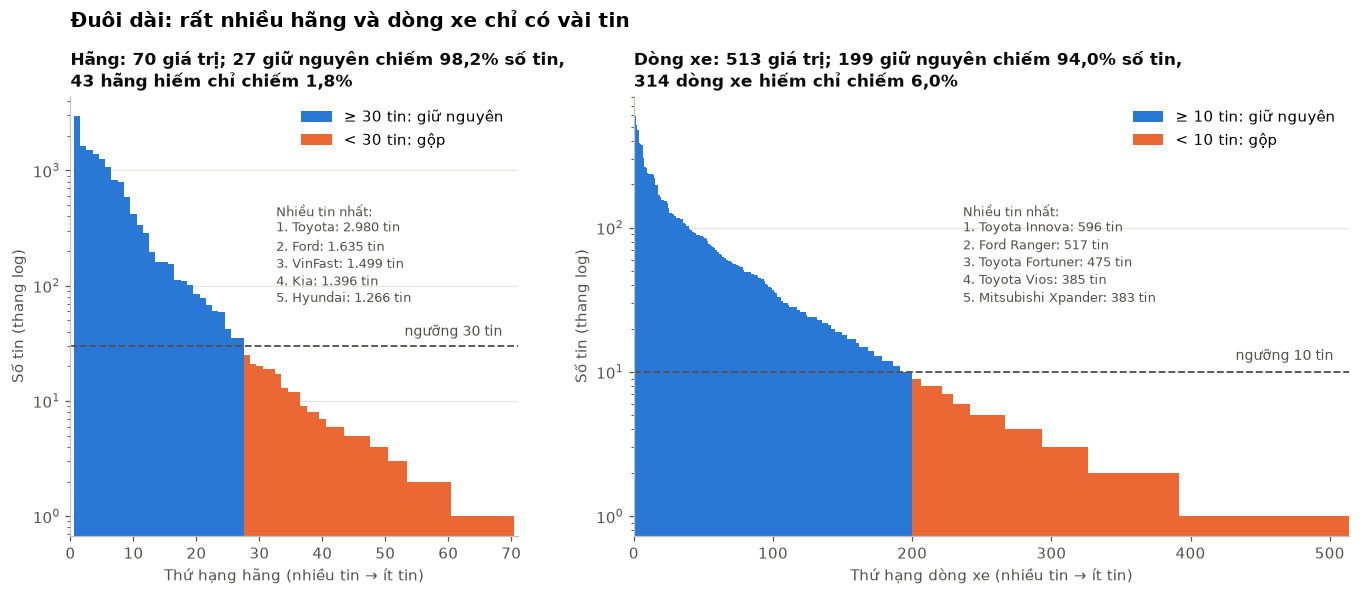

,số giá trị,≥ ngưỡng,< ngưỡng,chỉ 1 tin,trung vị số tin
Hãng (ngưỡng 30),70,27,43,10,12.0
Dòng xe (ngưỡng 10),513,199,314,122,5.0


In [7]:
BRAND_MIN, MODEL_MIN = 30, 10
cnt_brand = raw["carbrand"].value_counts()
cnt_model = (raw["carbrand"] + " " + raw["carmodel"]).value_counts()

def long_tail(ax, cnt, thr, what, label_top=5):
    rank = np.arange(1, len(cnt) + 1)
    above = cnt.values >= thr
    ax.bar(rank[above], cnt.values[above], width=1.0, color=BLUE, label=f"≥ {thr} tin: giữ nguyên")
    ax.bar(rank[~above], cnt.values[~above], width=1.0, color=ORANGE, label=f"< {thr} tin: gộp")
    ax.axhline(thr, color=INK2, lw=1.2, ls="--")
    ax.text(len(cnt) * 0.98, thr * 1.15, f"ngưỡng {thr} tin", ha="right", va="bottom", color=INK2, fontsize=9)
    ax.set_yscale("log"); ax.set_xlim(0, len(cnt) + 1)
    ax.set_xlabel(f"Thứ hạng {what} (nhiều tin → ít tin)"); ax.set_ylabel("Số tin (thang log)")
    ax.grid(axis="x", visible=False)
    top = "\n".join(f"{k + 1}. {cnt.index[k]}: {vn(cnt.values[k])} tin" for k in range(label_top))
    ax.text(0.46, 0.76, "Nhiều tin nhất:\n" + top, transform=ax.transAxes, va="top", ha="left",
            fontsize=8.5, color=INK2, linespacing=1.35)
    n_keep, n_rare = above.sum(), (~above).sum()
    cover = cnt.values[above].sum() / cnt.sum() * 100
    ax.set_title(f"{what.capitalize()}: {vn(len(cnt))} giá trị; {vn(n_keep)} giữ nguyên chiếm {vn(cover, 1)}% số tin,\n"
                 f"{vn(n_rare)} {what} hiếm chỉ chiếm {vn(100 - cover, 1)}%", fontsize=11)
    ax.legend(frameon=False, loc="upper right")
    return n_keep, n_rare, cover

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.2})
long_tail(axes[0], cnt_brand, BRAND_MIN, "hãng")
long_tail(axes[1], cnt_model, MODEL_MIN, "dòng xe")
fig.suptitle("Đuôi dài: rất nhiều hãng và dòng xe chỉ có vài tin", x=0.125, ha="left",
             fontsize=13, fontweight="bold", y=1.03)
save(fig, "v05_duoi_dai_hang_dong")

tail = pd.DataFrame({
    "số giá trị": [len(cnt_brand), len(cnt_model)],
    "≥ ngưỡng": [(cnt_brand >= BRAND_MIN).sum(), (cnt_model >= MODEL_MIN).sum()],
    "< ngưỡng": [(cnt_brand < BRAND_MIN).sum(), (cnt_model < MODEL_MIN).sum()],
    "chỉ 1 tin": [(cnt_brand == 1).sum(), (cnt_model == 1).sum()],
    "trung vị số tin": [cnt_brand.median(), cnt_model.median()],
}, index=["Hãng (ngưỡng 30)", "Dòng xe (ngưỡng 10)"])
tail

**Đọc biểu đồ:**
- Cả hai cột có dạng **đuôi dài**: vài nhãn đầu bảng (Toyota gần 3.000 tin, Ford, VinFast, Kia, Hyundai trên 1.200 tin; dòng Toyota Innova, Ford Ranger, Toyota Fortuner 475-596 tin) có hàng trăm đến hàng nghìn tin, còn phần lớn nhãn chỉ có vài tin.
- **Dòng xe:** 314/513 dòng (61%) nằm dưới ngưỡng 10 tin, 122 dòng chỉ có **đúng 1 tin**; trung vị chỉ 5 tin mỗi dòng. Mô hình không thể học giá của một dòng xe từ 1-2 ví dụ; one-hot nguyên vẹn sẽ sinh hàng trăm cột gần như rỗng, và một dòng chỉ có ở tập test thì mô hình chưa từng thấy.
- Nhưng các nhãn hiếm này chỉ chiếm **khoảng 6% số tin** (dòng xe) và **khoảng 2%** (hãng). Gộp chúng lại giảm mạnh số cột mà gần như không mất dữ liệu.
- **Gộp vào đâu:** dòng hiếm lùi về `"<Hãng> - dòng khác"` (vẫn giữ thông tin hãng), hãng hiếm lùi về `"Hãng cao cấp khác"` / `"Hãng phổ thông khác"`. Ngưỡng 30 / 10 được chọn bằng CV trên tập train (mục 7.4 của `preprocess_data.ipynb`).

*Số liệu ở đây tính trên dữ liệu thô (còn tin trùng) nên hơi khác số sau làm sạch (69 hãng, 509 dòng → 28 và 214 nhóm).*